## **Exercise 3 - Regularisation and Generalisation**

This exercise investigates how two regularisation techniques, **dropout** and **data augmentation**, affect the generalisation of the CNN from Exercise 2 on CIFAR-10. Each technique is first evaluated **independently** against the unchanged CNN baseline. A combined configuration is then tested to check whether the two techniques interact.

**Experimental Setup**
- **Baseline model:** the Exercise 2 CNN - Conv(3→32) → Pool → Conv(32→64) → Pool → Linear(4096→10), 60,362 trainable parameters.
- **Configurations:** Baseline · Dropout (p = 0.5) · Data augmentation · Dropout + augmentation.
- **Data:** the same 45,000 / 5,000 train/validation split as Exercises 1-2 (seed 42); the 10,000-image test set is used once per run.
- **Training:** 30 epochs, Adam optimiser, learning rate 0.001, batch size 128; best epoch selected on validation accuracy.
- **Evaluation:** 3 random seeds (0, 1, 2) per configuration (12 runs). We report mean ± standard deviation of training, validation and test accuracy and the train - test generalisation gap, and test the differences with Welch's t-test.


**1. Importing Libraries and Setting Up the Environment**

In [ ]:
import os, time, copy, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

# Setting the main training parameters
EPOCHS = 30
LR = 1e-3
BATCH_SIZE = 128
NUM_WORKERS = 2
ROOT = "./data"
os.makedirs("figures", exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available()
                      else "mps" if torch.backends.mps.is_available() else "cpu")
print("Using device:", DEVICE)

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

Using device: cuda


**2. Loading the CIFAR-10 Dataset and Preparing Data Loaders**

In [ ]:
CLASSES = ["aeroplane","automobile","bird","cat","deer","dog","frog","horse","ship","truck"]
MEAN, STD = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616) # CIFAR-10 normalization values

# Preparing the transformations used for evaluation and training
eval_tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

# Applying light augmentation to make the training images more varied
aug_tf = transforms.Compose([
    transforms.RandomAffine(degrees=10, translate=(0.1, 0.1)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

train_eval_full = datasets.CIFAR10(ROOT, train=True,  download=True,  transform=eval_tf)
train_aug_full  = datasets.CIFAR10(ROOT, train=True,  download=False, transform=aug_tf)
test_set        = datasets.CIFAR10(ROOT, train=False, download=True,  transform=eval_tf)


perm = torch.randperm(50000, generator=torch.Generator().manual_seed(42)).tolist()
train_idx, val_idx = perm[:45000], perm[45000:]
print(f"train={len(train_idx)}  val={len(val_idx)}  test={len(test_set)}")

def make_loaders(augment=False, seed=0):
# Using augmented images only when augmentation is enabled
    g = torch.Generator().manual_seed(seed)
    src = train_aug_full if augment else train_eval_full
    train_loader = DataLoader(Subset(src, train_idx), batch_size=BATCH_SIZE, shuffle=True,
                              num_workers=NUM_WORKERS, generator=g)
    clean_train = DataLoader(Subset(train_eval_full, train_idx), batch_size=512, num_workers=NUM_WORKERS)
    val_loader  = DataLoader(Subset(train_eval_full, val_idx),   batch_size=512, num_workers=NUM_WORKERS)
    test_loader = DataLoader(test_set, batch_size=512, num_workers=NUM_WORKERS)
    return train_loader, clean_train, val_loader, test_loader

100%|██████████| 170M/170M [25:40<00:00, 111kB/s]


train=45000  val=5000  test=10000


 **Regularisation Rationale**

**Data augmentation** (`aug_tf`) is applied only to training images. It is generated randomly every time an image is loaded, so the network sees a slightly different version of each image in every epoch,
- `RandomAffine(degrees=10)` - small rotations, since photographed objects are rarely perfectly upright.
- `translate=(0.1, 0.1)` - shifts of up to 10% (about 3 pixels), so the exact position of the object does not matter.
- `RandomHorizontalFlip()` - mirroring. This keeps the label correct for every CIFAR-10 class (a left-facing horse is still a horse). Vertical flips are **not** used because an upside-down ship or truck is unrealistic.

The transformations are deliberately small, so images still look natural and labels stay correct. Validation and test images always use `eval_tf` (no augmentation), so evaluation measures performance on real, unchanged images.

The split uses the same `torch.randperm(..., seed 42)` as Exercises 2 and 4. This gives exactly the same indices as `random_split` with seed 42 in Exercise 1, so every exercise uses identical partitions.

**3. Model Evaluation Functions**

In [ ]:
# Count the number of trainable parameters in a model
def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


# Run one epoch and calculate the average loss and accuracy
def run_epoch(model, loader, optimizer=None):
    train = optimizer is not None
    model.train(train)
    tot_loss = tot_correct = n = 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            out = model(x)
            loss = F.cross_entropy(out, y)
            if train:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            tot_loss += loss.item() * len(y)
            tot_correct += (out.argmax(1) == y).sum().item()
            n += len(y)
    return tot_loss / n, tot_correct / n

**4. Model Training and Validation**

In [ ]:
def train_model(model, loaders, epochs=EPOCHS, lr=LR, verbose=True):
    # Using Adam and cross-entropy loss to train the model
    train_loader, clean_train, val_loader, test_loader = loaders
    model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {k: [] for k in ["train_loss", "val_loss", "train_acc", "val_acc"]}
    best_val, best_state, best_epoch, t0 = -1, None, 0, time.time()

    for ep in range(1, epochs + 1):
        tl, ta = run_epoch(model, train_loader, opt)
        vl, va = run_epoch(model, val_loader)

        for k, v in zip(hist, [tl, vl, ta, va]): hist[k].append(v)

        # Keeping the model from the epoch with the highest validation accuracy
        if va > best_val:
            best_val, best_epoch, best_state = va, ep, copy.deepcopy(model.state_dict())

        if verbose and (ep % 5 == 0 or ep == 1):
            print(f"ep {ep:02d} | train loss {tl:.3f} acc {ta:.3f} | val loss {vl:.3f} acc {va:.3f}")

    # Restoring the best model before evaluating
    model.load_state_dict(best_state)
    ctl, cta = run_epoch(model, clean_train)
    vl, va = run_epoch(model, val_loader)
    tel, tea = run_epoch(model, test_loader)

    res = dict(params=count_params(model), best_epoch=best_epoch, train_loss=ctl, train_acc=cta,
               val_loss=vl, val_acc=va, test_loss=tel, test_acc=tea, gap=cta - tea,
               final_epoch_train_loss=hist["train_loss"][-1], time_s=time.time() - t0)
    return hist, res

**Clean-Image Training Accuracy**

Epoch accuracy uses augmented images and active dropout, understating model performance. Therefore, training accuracy is re-measured on original images with dropout disabled.

This ensures fair comparison across all four configurations. The best validation checkpoint is used, and the test set is evaluated only once.

**5. Performance Visualization and Confusion Matrix**

In [ ]:
# Plot training and validation loss and accuracy across epochs
def plot_history(hist, title, fname=None):
    ep = range(1, len(hist["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    ax[0].plot(ep, hist["train_loss"], label="Training"); ax[0].plot(ep, hist["val_loss"], label="Validation")
    ax[0].set(title=f"{title}: loss", xlabel="Epoch", ylabel="Cross-entropy loss"); ax[0].legend(); ax[0].grid(alpha=.3)
    ax[1].plot(ep, hist["train_acc"], label="Training"); ax[1].plot(ep, hist["val_acc"], label="Validation")
    ax[1].set(title=f"{title}: accuracy", xlabel="Epoch", ylabel="Accuracy"); ax[1].legend(); ax[1].grid(alpha=.3)
    plt.tight_layout()
    if fname: plt.savefig(f"figures/{fname}.png", dpi=200)
    plt.show()


# confusion matrix from predictions
@torch.no_grad()
def confusion(model, loader):
    model.eval(); cm = np.zeros((10, 10), dtype=int)
    for x, y in loader:
        p = model(x.to(DEVICE)).argmax(1).cpu().numpy()
        for t, q in zip(y.numpy(), p): cm[t, q] += 1
    return cm



def plot_confusion(cm, title, fname=None):
    plt.figure(figsize=(6.2, 5.4)); plt.imshow(cm, cmap="Blues"); plt.colorbar()
    plt.xticks(range(10), CLASSES, rotation=60, ha="right"); plt.yticks(range(10), CLASSES)
    for i in range(10):
        for j in range(10):
            plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=6,
                     color="white" if cm[i, j] > cm.max() / 2 else "black")
    plt.title(title); plt.xlabel("Predicted"); plt.ylabel("True"); plt.tight_layout()
    if fname: plt.savefig(f"figures/{fname}.png", dpi=200)
    plt.show()

**6. The MLP and CNN Architectures**

In [ ]:
# Defining a simple MLP
class MLP(nn.Module):
    # Three trainable layers
    def __init__(self, h1=512, h2=256):
        super().__init__()
        self.net = nn.Sequential(nn.Flatten(), nn.Linear(3 * 32 * 32, h1), nn.ReLU(),
                                 nn.Linear(h1, h2), nn.ReLU(), nn.Linear(h2, 10))

    def forward(self, x):
        return self.net(x)  # Return raw predictions (logits)


# Building a CNN with configurable channels and dropout
def build_cnn(channels, dropout=0.0, max_pools=3, n_classes=10):
    # Addding convolution, activation and pooling layer
    layers, c = [], 3
    for i, ch in enumerate(channels):
        layers += [nn.Conv2d(c, ch, 3, padding=1), nn.ReLU()]
        if i < max_pools: layers.append(nn.MaxPool2d(2))
        c = ch

    layers.append(nn.Flatten())

    # Calculating the flattened feature size before adding the final layer
    with torch.no_grad():
        d = nn.Sequential(*layers)(torch.zeros(1, 3, 32, 32)).shape[1]

    if dropout > 0:
        layers.append(nn.Dropout(dropout))

    layers.append(nn.Linear(d, n_classes))
    return nn.Sequential(*layers)

**Architecture and Dropout**

All experiments use the same baseline CNN (build_cnn([32, 64])). The MLP is retained for shared code but is not trained.
- Dropout (p = 0.5): Applied after Flatten, before the final linear layer, which contains 68% of the model's parameters and is most prone to memorisation.
- Justification: Based on Srivastava et al. (2014), p = 0.5 is recommended for fully connected layers.
- Evaluation: Dropout is automatically disabled in model.eval().
- Parameter count: Dropout adds no trainable parameters, so all configurations retain 60,362 parameters.

**7. Running Experiments Across Different Configurations and Seeds**

In [ ]:
import json

SEEDS = [0, 1, 2]

# Defining the configurations
CONFIGS = {
    "Baseline":           dict(dropout=0.0, augment=False),
    "Dropout (p=0.5)":    dict(dropout=0.5, augment=False),
    "Augmentation":       dict(dropout=0.0, augment=True),
    "Dropout + Augment.": dict(dropout=0.5, augment=True),
}

# Saving progress after each run
CKPT = "ex3_checkpoint.json"
rows, hists = [], {}


if os.path.exists(CKPT):
    saved = json.load(open(CKPT))
    rows = saved["rows"]
    hists = {(k.rsplit("||", 1)[0], int(k.rsplit("||", 1)[1])): v for k, v in saved["hists"].items()}
    print(f"Resuming: {len(rows)} runs already finished")

done = {(r["config"], r["seed"]) for r in rows}

# Training each config using the selected random seeds
for name, cfg in CONFIGS.items():
    for s in SEEDS:
        if (name, s) in done:
            print(f"{name:20s} seed {s}: already done, skipping")
            continue

        set_seed(s)
        loaders = make_loaders(augment=cfg["augment"], seed=s)
        model = build_cnn([32, 64], dropout=cfg["dropout"])

        h, r = train_model(model, loaders, verbose=False)

        # Storing the results and training history for each run
        rows.append(dict(config=name, seed=s, **r))
        hists[(name, s)] = h

        # Updating the checkpoint after every completed run
        json.dump({"rows": rows, "hists": {f"{k[0]}||{k[1]}": v for k, v in hists.items()}}, open(CKPT, "w"))

        print(f"{name:20s} seed {s}: train {r['train_acc']:.3f} val {r['val_acc']:.3f} test {r['test_acc']:.3f} gap {r['gap']:.3f}"
              f" | {r['time_s']/60:.1f} min")

# Save results in a CSV file
raw = pd.DataFrame(rows)
raw.to_csv("ex3_raw_results.csv", index=False)

Baseline             seed 0: train 0.862 val 0.714 test 0.718 gap 0.145 | 6.2 min
Baseline             seed 1: train 0.847 val 0.714 test 0.708 gap 0.139 | 6.2 min
Baseline             seed 2: train 0.842 val 0.720 test 0.715 gap 0.127 | 6.1 min
Dropout (p=0.5)      seed 0: train 0.861 val 0.763 test 0.756 gap 0.104 | 6.2 min
Dropout (p=0.5)      seed 1: train 0.849 val 0.752 test 0.752 gap 0.097 | 6.2 min
Dropout (p=0.5)      seed 2: train 0.866 val 0.761 test 0.761 gap 0.105 | 6.1 min
Augmentation         seed 0: train 0.796 val 0.762 test 0.767 gap 0.029 | 8.7 min
Augmentation         seed 1: train 0.797 val 0.765 test 0.766 gap 0.032 | 8.7 min
Augmentation         seed 2: train 0.790 val 0.762 test 0.764 gap 0.026 | 8.9 min
Dropout + Augment.   seed 0: train 0.769 val 0.746 test 0.750 gap 0.019 | 8.9 min
Dropout + Augment.   seed 1: train 0.772 val 0.750 test 0.752 gap 0.021 | 8.9 min
Dropout + Augment.   seed 2: train 0.775 val 0.757 test 0.752 gap 0.023 | 8.9 min


**Training Run Analysis**

Each configuration uses three seeds with identical settings, isolating the effects of regularisation. Augmentation increases training time (8.8 vs. 6.2 minutes) due to CPU-based image transformations. Progress is saved in ex3_checkpoint.json to allow interrupted runs to resume.

**8. Experiment result summary comparative table (mean +/- std over seeds)**

In [ ]:
# Calculating the mean and standard deviation for each config
def ms(c):
    return raw.groupby("config", sort=False)[c].agg(lambda x: f"{x.mean()*100:.2f} +/- {x.std()*100:.2f}")

summary = pd.DataFrame({
    "Train acc (%)": ms("train_acc"),
    "Val acc (%)": ms("val_acc"),
    "Test acc (%)": ms("test_acc"),
    "Train-Test gap (pp)": ms("gap")
})

display(summary)
summary.to_csv("ex3_summary.csv")

,Train acc (%),Val acc (%),Test acc (%),Train-Test gap (pp)
config,,,,
Baseline,85.01 +/- 1.08,71.59 +/- 0.36,71.34 +/- 0.49,13.68 +/- 0.89
Dropout (p=0.5),85.86 +/- 0.90,75.89 +/- 0.57,75.65 +/- 0.48,10.21 +/- 0.45
Augmentation,79.45 +/- 0.38,76.33 +/- 0.18,76.56 +/- 0.12,2.89 +/- 0.29
Dropout + Augment.,77.21 +/- 0.30,75.09 +/- 0.59,75.12 +/- 0.09,2.08 +/- 0.21


**Results Interpretation**

- **Both techniques improve generalisation -** Each raises test accuracy by more than 4 pp, and the standard deviations (≤ 0.6 pp) are much smaller than these improvements, so the effect is not caused by random variation between seeds.
- **Augmentation is the most effective -** It is the only technique that *lowers* training accuracy (85.0% → 79.5%) while *raising* test accuracy. The model can no longer memorise the exact training images, so the gap drops from 13.7 pp to 2.9 pp. It is also the most consistent configuration (test SD only 0.12 pp).
- **Dropout improves accuracy but leaves a large gap -** Training accuracy stays at about 86%, so the gap only falls to 10.2 pp. Dropout regularises only the final layer, the convolutional filters can still fit the training images.
- **Combining both is not better -** The gap is the smallest (2.1 pp), but test accuracy is lower than with augmentation alone, and training accuracy (77.2%) is close to test accuracy. This suggests the small network is starting to **underfit**, two strong regularisers remove more capacity than a 60,000-parameter model can afford. Section 12 tests this further.

**9. Statistical Significance of the Differences**

In [ ]:
# Welch's t-test on the 3 per-seed results of each configuration
#p < 0.05 indicates a statistically significant difference
from scipy import stats

def welch(a, b, metric="test_acc"):
    x = raw.loc[raw.config == a, metric]
    y = raw.loc[raw.config == b, metric]
    return (y.mean() - x.mean()) * 100, stats.ttest_ind(x, y, equal_var=False).pvalue

pairs = [("Baseline", "Dropout (p=0.5)"), ("Baseline", "Augmentation"),
         ("Baseline", "Dropout + Augment."), ("Dropout (p=0.5)", "Augmentation"),
         ("Augmentation", "Dropout + Augment.")]

sig = pd.DataFrame([(a, b, *welch(a, b), *welch(a, b, "gap")) for a, b in pairs],
                   columns=["A", "B", "Test acc diff B-A (pp)", "p (test acc)",
                            "Gap diff B-A (pp)", "p (gap)"]).round(4)
display(sig)
sig.to_csv("ex3_significance.csv", index=False)


,A,B,Test acc diff B-A (pp),p (test acc),Gap diff B-A (pp),p (gap)
0,Baseline,Dropout (p=0.5),4.3133,0.0004,-3.4667,0.0097
1,Baseline,Augmentation,5.2233,0.0019,-10.7885,0.0009
2,Baseline,Dropout + Augment.,3.7867,0.0044,-11.5933,0.0012
3,Dropout (p=0.5),Augmentation,0.9100,0.0744,-7.3219,0.0001
4,Augmentation,Dropout + Augment.,-1.4367,0.0001,-0.8048,0.0218


**Significance Test Results**

- All regularised models outperform baseline (p = 0.0004–0.0044).
- **Dropout vs. augmentation -** Accuracy difference is not significant (p = 0.074), but the generalisation gap differs significantly (p = 0.0001).
- **Combined approach -** Performs significantly worse than augmentation alone (p = 0.0001), supporting possible underfitting.
- **Limitation -** With only three seeds, statistical power is limited. Non-significance does not imply identical performance.

**10. Comparing Model Performance Across Configurations**

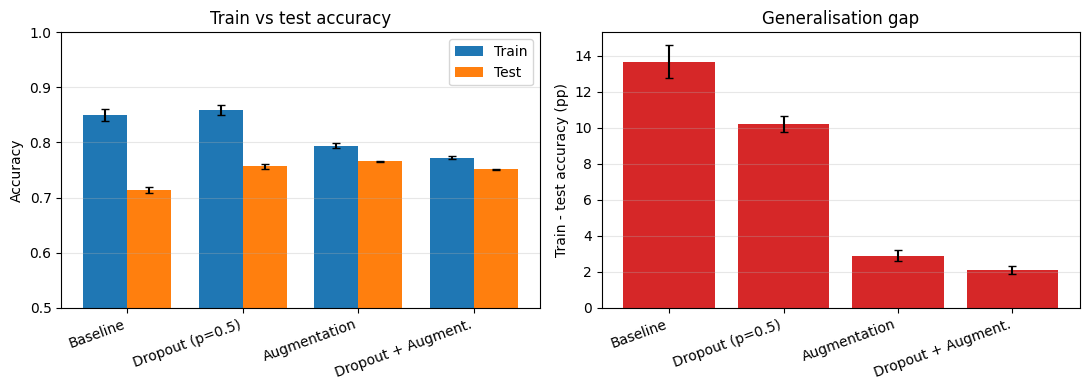

In [ ]:
# Comparing training accuracy, test accuracy and generalisation gap
g = raw.groupby("config", sort=False)[["train_acc", "test_acc", "gap"]].agg(["mean", "std"])

x = np.arange(len(g))
w = 0.38

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

# Comparing training and test accuracy
ax[0].bar(x - w/2, g[("train_acc", "mean")], w, yerr=g[("train_acc", "std")], label="Train", capsize=3)
ax[0].bar(x + w/2, g[("test_acc", "mean")], w, yerr=g[("test_acc", "std")], label="Test", capsize=3)
ax[0].set_xticks(x)
ax[0].set_xticklabels(g.index, rotation=20, ha="right")
ax[0].set_ylim(0.5, 1.0)
ax[0].set(ylabel="Accuracy", title="Train vs test accuracy")
ax[0].legend()
ax[0].grid(axis="y", alpha=.3)

# Comparing the generalisation gap between configs
ax[1].bar(x, g[("gap", "mean")] * 100, yerr=g[("gap", "std")] * 100, capsize=3, color="tab:red")
ax[1].set_xticks(x)
ax[1].set_xticklabels(g.index, rotation=20, ha="right")
ax[1].set(ylabel="Train - test accuracy (pp)", title="Generalisation gap")
ax[1].grid(axis="y", alpha=.3)

plt.tight_layout()
plt.savefig("figures/ex3_comparison.png", dpi=200)
plt.show()

**Accuracy and Gap Comparison**

- The left graph shows that regularisation reduces training accuracy while improving test accuracy, bringing the two closer together. Augmentation shows the clearest improvement.

- The right graph shows the generalisation gap decreasing from 13.7 pp (baseline) to 10.2 pp (dropout), 2.9 pp (augmentation) and 2.1 pp (combined). Small error bars indicate consistent results across seeds.

- However, a smaller gap does not always mean better performance. Although the combined model has the smallest gap, its test accuracy is lower than augmentation alone. Augmentation provides the best balance between test accuracy and generalisation.

**11. Comparing Training and Validation Loss Curves**

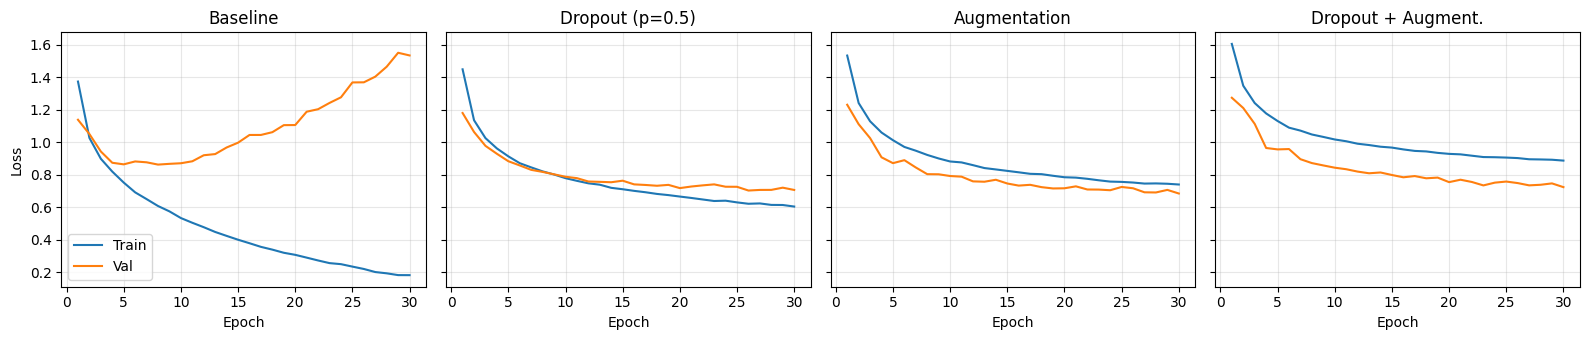

In [ ]:
# Comparing how training and validation loss change across configs
fig, ax = plt.subplots(1, 4, figsize=(16, 3.5), sharey=True)

for a, name in zip(ax, CONFIGS):
    h = hists[(name, 0)]
    e = range(1, EPOCHS + 1)

    a.plot(e, h["train_loss"], label="Train")
    a.plot(e, h["val_loss"], label="Val")
    a.set(title=name, xlabel="Epoch")
    a.grid(alpha=.3)

ax[0].set_ylabel("Loss")
ax[0].legend()

plt.tight_layout()
plt.savefig("figures/ex3_loss_curves.png", dpi=200)
plt.show()

**Loss Curves (Seed 0)**

- **Baseline -** Training loss decreases, but validation loss rises after epoch 5 (0.86 → 1.55), indicating clear overfitting.
- **Dropout -** Validation loss stabilises around 0.71, reducing overfitting, although training loss continues to decrease.
- **Augmentation -** Validation loss decreases throughout training, reaching 0.69 at epoch 30, indicating strong generalisation and potential for further improvement.
- **Combined -** Training loss remains higher than validation loss (0.89 vs. 0.72), suggesting strong regularisation and possible underfitting.
Training loss can exceed validation loss because training uses augmented images and active dropout, making it harder than clean validation data with dropout disabled.

Overall, augmentation provides the strongest control over overfitting, while combining both techniques may over-regularise the model.

**12. Supplementary Experiment - Extended Training (60 Epochs)**

Section 11 shows that both augmented models still had decreasing validation loss at epoch 30. Therefore, augmentation and the combined approach are retrained for 60 epochs (seed 0) to determine whether lower accuracy results from insufficient training or limited model capacity.

Augmentation         60 ep: best epoch 59 | train 0.825 val 0.789 test 0.791 gap 0.035 | 17.7 min
Dropout + Augment.   60 ep: best epoch 60 | train 0.795 val 0.769 test 0.769 gap 0.026 | 17.6 min


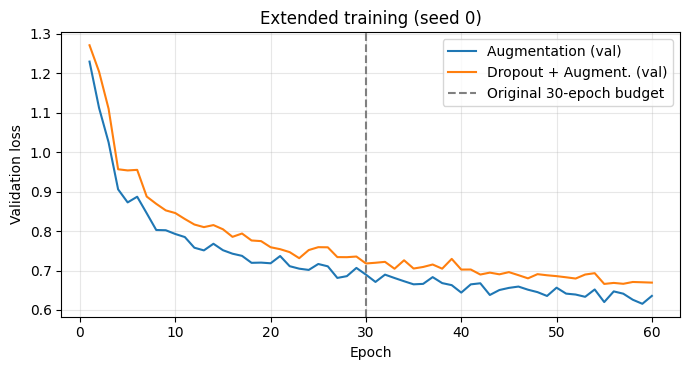

In [ ]:
# are the augmented models under-trained at 30 epochs?
# Same setup as the main runs (seed 0) but 60 epochs.
EXT_EPOCHS = 60
ext_rows, ext_hists = [], {}

for name in ["Augmentation", "Dropout + Augment."]:
    cfg = CONFIGS[name]
    set_seed(0)
    loaders = make_loaders(augment=cfg["augment"], seed=0)
    model = build_cnn([32, 64], dropout=cfg["dropout"])
    h, r = train_model(model, loaders, epochs=EXT_EPOCHS, verbose=False)
    ext_rows.append(dict(config=name, epochs=EXT_EPOCHS, **r))
    ext_hists[name] = h
    print(f"{name:20s} 60 ep: best epoch {r['best_epoch']} | train {r['train_acc']:.3f} "
          f"val {r['val_acc']:.3f} test {r['test_acc']:.3f} gap {r['gap']:.3f} | {r['time_s']/60:.1f} min")

ext = pd.DataFrame(ext_rows)
ext.to_csv("ex3_extended_60ep.csv", index=False)

# Validation loss over 60 epochs for both configurations
plt.figure(figsize=(7, 3.8))
for name, h in ext_hists.items():
    plt.plot(range(1, EXT_EPOCHS + 1), h["val_loss"], label=f"{name} (val)")
plt.axvline(30, ls="--", c="grey", label="Original 30-epoch budget")
plt.xlabel("Epoch"); plt.ylabel("Validation loss"); plt.title("Extended training (seed 0)")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig("figures/ex3_extended_60ep.png", dpi=200); plt.show()

**Extended Training Results**

| Configuration (seed 0) | Test acc, 30 epochs | Test acc, 60 epochs | Gain | Best epoch (60-epoch run) |
|---|---|---|---|---|
| Augmentation | 76.7% | **79.1%** | +2.4 pp | 59 |
| Dropout + Aug. | 75.0% | 76.9% | +1.9 pp | 60 |

- **Both models were under-trained -** Test accuracy improved by around 2 pp, with the best epochs occurring at 59 and 60.
- **Combination remains weaker -** It trails augmentation by 2.2 pp, suggesting limited model capacity rather than insufficient training time alone.
- **Overfitting remains controlled -** Both models maintain small generalisation gaps (3.5 and 2.6 pp).

**Conclusion**

Longer training improves both models, but augmentation alone remains more effective. A larger network may help the combined approach.

*Note: These are single-seed results and indicate trends rather than statistically confirmed differences.*

**Overall Conclusion**

Both techniques improved the CNN's generalisation, but with different effectiveness.

1. Data augmentation performed best, achieving 76.56% test accuracy with a 2.9 pp gap. It reduces memorisation by exposing the model to varied images. Extending training to 60 epochs increased accuracy to 79.1%.

2. Dropout improved test accuracy (75.65%) and stabilised validation loss, but the generalisation gap remained relatively high (10.2 pp).

3. Combining both produced the smallest gap but significantly lower test accuracy than augmentation alone (p = 0.0001), suggesting limited model capacity rather than insufficient training time.

**Final thoughts**

For a network of this size, data augmentation alone, trained for longer, is the best choice. A larger network or a lower dropout rate (for example p = 0.25) would likely be needed for the combination to outperform augmentation on its own.
